# Classificação de imagens naturais com MobileNetV2
### Inteligência Computacional / Machine Learning — Defesa intermediária • 2026.2
**Equipe:** [preencher nomes dos integrantes]  
**Docente:** Profa. Polyana Santos Fonseca Nascimento  
**Família:** MobileNet | **Versão:** MobileNetV2 | **Framework:** TensorFlow/Keras

**Declaração de uso de IA generativa (revisar antes da entrega).** Ferramenta: ChatGPT (OpenAI). Finalidade: apoio à pesquisa bibliográfica, organização da metodologia, elaboração da primeira versão do código e revisão conceitual. Extensão: contribuição substancial na redação e implementação desta versão inicial; a equipe deve atualizar esta descrição conforme suas próprias alterações e trabalho efetivo. Medidas de validação previstas: confrontar explicações com o artigo original e documentação oficial, executar todas as células, conferir divisões, parâmetros, métricas e exemplos visualmente, revisar resultados e explicar as decisões de forma autônoma. Ainda não se declara nenhuma dessas validações como concluída pela equipe.

**Escopo:** pesquisa, análise/preparação dos dados, baseline com base congelada, avaliação exclusivamente na validação, análise visual preliminar e planejamento de duas estratégias de fine-tuning. O teste fica reservado. Treinamento A/B, Grad-CAM comparativo, escolha final, teste e inferência externa ficam para a versão final.

## 1. Problema e justificativa do dataset
O objetivo é classificar uma imagem RGB em exatamente uma entre oito categorias: avião, carro, gato, cachorro, flor, fruta, motocicleta e pessoa. A variável-alvo é categórica nominal; o rótulo deriva do diretório de origem. Trata-se de classificação multiclasse de rótulo único, e não detecção de objetos ou classificação multilabel.

O [Natural Images](https://www.kaggle.com/datasets/prasunroy/natural-images), compilado por Prasun Roy e colaboradores, é descrito como um conjunto de 6.899 imagens de oito categorias. Uma aplicação possível é a triagem/organização automática de coleções de fotos em dispositivos com recursos limitados, sem afirmar que já existe um produto validado. A MobileNetV2 é adequada como candidata por seu compromisso entre custo e qualidade; pesos ImageNet permitem aproveitar representações anteriores em vez de iniciar do zero.

O conjunto reúne imagens de origens diferentes (ver [repositório dos autores](https://github.com/prasunroy/cnn-on-degraded-images)). Isso pode introduzir atalhos por fundo, enquadramento, resolução ou origem de coleta; a classe pessoa, por exemplo, pode coexistir com uma motocicleta, embora haja só um rótulo. O modelo não reconhece classes fora das oito previstas. A adequação à lauda quanto a datasets já utilizados em sala ou amplamente documentados depende da confirmação da professora; o conjunto tem exemplos públicos de uso e não assumimos que esse requisito está automaticamente satisfeito.

## 2. Pesquisa da arquitetura
**Referência principal:** Sandler, M.; Howard, A.; Zhu, M.; Zhmoginov, A.; Chen, L.-C. *MobileNetV2: Inverted Residuals and Linear Bottlenecks*. CVPR, 2018, p. 4510–4520. [Artigo original](https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html) · [DOI](https://doi.org/10.1109/CVPR.2018.00474).

### 2.1 Convoluções separáveis em profundidade
Uma convolução convencional combina informação espacial e entre canais em uma única operação. A MobileNet separa essas funções: **depthwise** (um filtro espacial por canal, para multiplicador 1) e **pointwise** (convolução 1×1 que mistura canais). Para saída espacial H×W, kernel K×K, M canais de entrada e N de saída, ignorando viés e BN:

- Conv convencional: H·W·K²·M·N multiplicações-acumulações (MACs).
- Depthwise + pointwise: H·W·(K²·M + M·N) MACs.
- Razão separável/convencional: 1/N + 1/K². Exemplo K=3, M=32, N=64: 18.432 versus 2.336 pesos, cerca de 7,9 vezes menos para esse par de operações. Isso não representa automaticamente o ganho de toda a rede, pois a V2 inclui expansão e outras camadas.

### 2.2 Diferenciais da V2
A V1 já utilizava convoluções separáveis. A V2 combina a separação com **resíduos invertidos e gargalos lineares**. Um bloco típico começa com poucos canais, expande por 1×1, aplica depthwise 3×3 e projeta de volta a poucos canais por 1×1. A expansão (geralmente fator 6) e a depthwise são seguidas de Batch Normalization e ReLU6 (`min(max(x,0),6)`). A projeção usa BN, sem ReLU: a não linearidade em um espaço estreito poderia eliminar informação útil. A conexão residual soma entrada e saída somente se stride=1 e as formas coincidirem; ela facilita o fluxo de gradientes. O resíduo é invertido porque conecta representações estreitas, em contraste com o gargalo residual clássico da ResNet, que conecta representações mais largas. O primeiro bloco possui expansão t=1 e é uma exceção à expansão usual.

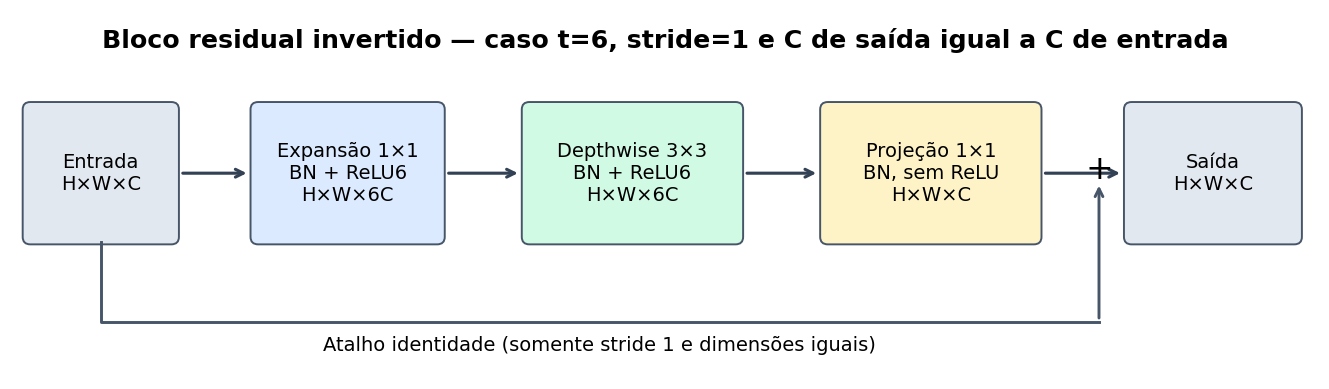

*Figura 1 — Esquema autoral desta versão, adaptado conceitualmente da Tabela 1 e Figuras 2–3 de Sandler et al. (2018). Consulte também as figuras originais no artigo.*

### 2.3 Fluxo global (alpha=1, entrada 224×224)
| Operação | Resolução de saída | Canais | Repetições |
|---|---:|---:|---:|
| Conv 3×3 | 112×112 | 32 | 1 |
| Bottleneck t=1 | 112×112 | 16 | 1 |
| Bottleneck t=6 | 56×56 | 24 | 2 |
| Bottleneck t=6 | 28×28 | 32 | 3 |
| Bottleneck t=6 | 14×14 | 64 | 4 |
| Bottleneck t=6 | 14×14 | 96 | 3 |
| Bottleneck t=6 | 7×7 | 160 | 3 |
| Bottleneck t=6 | 7×7 | 320 | 1 |
| Conv 1×1 | 7×7 | 1280 | 1 |
| Global Average Pooling | 1×1 | 1280 | 1 |
| Classificador adaptado | — | 8 | 1 |

Fonte: Tabela 2 do artigo, adaptada para o classificador deste trabalho. O classificador original de ImageNet (1.000 categorias) é removido. O multiplicador de largura alpha=1 mantém a largura padrão; a resolução de 224×224 segue a configuração de referência. Não alegamos latência móvel medida nesta versão.

**Transfer learning** reaproveita pesos aprendidos em ImageNet. Congelar a base significa impedir a atualização dos seus parâmetros durante o treinamento da nova cabeça. **Fine-tuning** significa ajustar também parte dos pesos pré-treinados, normalmente com taxa menor. O pipeline vai permitir comparar essas abordagens de modo controlado.

## 3. Ambiente, dependências e reprodutibilidade
Recomendação: Google Colab com GPU (ou Jupyter local com TensorFlow compatível). Na primeira execução é necessária internet para baixar dados e pesos ImageNet. Execute em ordem. Se instalar dependências em um ambiente já carregado, reinicie o kernel antes de continuar. Os arquivos de dados e modelos não devem entrar no Git; os manifestos pequenos de divisão podem ser versionados.

In [1]:
%pip install -q "tensorflow>=2.16,<2.22" "kagglehub>=0.3" "scikit-learn>=1.3" pandas matplotlib seaborn pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, hashlib, sys
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             balanced_accuracy_score, f1_score)
from IPython.display import display

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
LR = 1e-3
PATIENCE = 4
CLASSES = ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']
CLASSES_PT = ['avião', 'carro', 'gato', 'cachorro', 'flor', 'fruta', 'motocicleta', 'pessoa']
CLASS_TO_ID = dict(zip(CLASSES, range(len(CLASSES))))
N_CLASSES = len(CLASSES)
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
SPLITS = Path('splits')
SPLITS.mkdir(exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
# Solicita operações determinísticas quando suportadas pelo ambiente.
tf.config.experimental.enable_op_determinism()
print('Python:', sys.version.split()[0], '| GPU:', tf.config.list_physical_devices('GPU'))
for package in ['tensorflow', 'kagglehub', 'scikit-learn', 'numpy', 'pandas', 'Pillow']:
    print(package, version(package))

Python: 3.13.0 | GPU: []
tensorflow 2.20.0
kagglehub 1.0.3
scikit-learn 1.7.1
numpy 2.3.5
pandas 2.2.3
Pillow 11.0.0


## 4. Obtenção e inventário do dataset
KaggleHub baixa para o cache local. Se a equipe tiver uma cópia extraída, configure a variável de ambiente `NATURAL_IMAGES_DIR` para a pasta que contém as classes (ou sua pasta pai). A busca não contabiliza duas cópias de uma mesma estrutura. O total e as classes serão verificados antes de treinar. O inventário registra caminho relativo, dimensões, modo original e hash dos pixels RGB decodificados, útil para detectar duplicatas exatas. Não detecta todas as imagens quase duplicadas.

In [3]:
DATASET_HANDLE = 'prasunroy/natural-images'
local = os.environ.get('NATURAL_IMAGES_DIR')
root = Path(local).expanduser() if local else Path(kagglehub.dataset_download(DATASET_HANDLE))
assert root.is_dir(), f'Pasta inexistente: {root}'
candidates = [root, *sorted(root.rglob('natural_images'))]
valid = [p for p in candidates if p.is_dir() and all((p / c).is_dir() for c in CLASSES)]
assert valid, 'Não encontrei uma pasta com as oito classes.'
DATA_DIR = valid[0]
print('Pasta selecionada:', DATA_DIR)
rows, invalid = [], []
for cls in CLASSES:
    for path in sorted((DATA_DIR / cls).rglob('*')):
        if not path.is_file() or path.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.bmp'}:
            continue
        try:
            with Image.open(path) as im:
                im.load()
                width, height = im.size
                mode = im.mode
                rgb = im.convert('RGB')
                h = hashlib.sha256(f'{width}x{height}:'.encode() + rgb.tobytes()).hexdigest()
            rows.append((path.relative_to(DATA_DIR).as_posix(), cls, CLASS_TO_ID[cls], width, height, mode, h))
        except Exception as exc:
            invalid.append((str(path), str(exc)))
df = pd.DataFrame(rows, columns=['file', 'class', 'label', 'width', 'height', 'mode', 'sha256_rgb'])
print('Imagens válidas:', len(df), '| inválidas:', len(invalid))
if invalid:
    display(pd.DataFrame(invalid, columns=['file', 'error']))
assert not invalid, 'Investigar imagens inválidas e revisar divisão antes de prosseguir.'
assert len(df) == 6899 and df['class'].nunique() == 8, 'Versão/estrutura do dataset diferente da esperada.'
assert df['class'].value_counts().min() >= 100
counts = df['class'].value_counts().reindex(CLASSES)
display(pd.DataFrame({'classe': CLASSES_PT, 'n': counts.values, '%': (counts.values/len(df)*100).round(2)}))
print('Razão maior/menor classe:', round(counts.max()/counts.min(), 2))
print('Imagens além da primeira cópia de cada hash:', int(df.duplicated('sha256_rgb').sum()))
assert df.groupby('sha256_rgb')['label'].nunique().max() == 1, 'Duplicatas com rótulos conflitantes: revisar antes de dividir.'

100%|██████████| 342M/342M [00:40<00:00, 8.95MB/s] 

Extracting files...


Pasta selecionada: C:\Users\cactu\.cache\kagglehub\datasets\prasunroy\natural-images\versions\1\data\natural_images
Imagens válidas: 6899 | inválidas: 0


,classe,n,%
0,avião,727,10.54
1,carro,968,14.03
2,gato,885,12.83
3,cachorro,702,10.18
4,flor,843,12.22
5,fruta,1000,14.49
6,motocicleta,788,11.42
7,pessoa,986,14.29


Razão maior/menor classe: 1.42
Imagens além da primeira cópia de cada hash: 2


## 5. Holdout estratificado e reserva do teste
A equipe definiu 4.829 imagens de treino, 1.035 de validação e 1.035 de teste (aproximadamente 70/15/15). Primeiro separam-se 1.035 para teste e depois 1.035 para validação, com estratificação por classe e semente fixa. Caso duplicatas exatas atravessem os conjuntos, preservamos as cotas por classe da divisão original e realocamos grupos de hashes inteiros antes de distribuir imagens únicas. Isso evita que a mesma imagem apareça no treino e na avaliação. O manifesto é salvo e reutilizado: mudanças nos arquivos ou rótulos são sinalizadas. O teste não será carregado como tensor, previsto, exibido ou avaliado nesta versão. O inventário global e a contagem de classes são exclusivamente verificações de integridade e desenho do holdout.

In [4]:
df = df.drop(columns=['split'], errors='ignore').copy()
manifest_path = SPLITS / 'holdout.csv'
columns = ['file', 'class', 'label', 'sha256_rgb']
targets = {'train': 4829, 'val': 1035, 'test': 1035}
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    pd.testing.assert_frame_equal(manifest[columns].sort_values('file').reset_index(drop=True),
                                  df[columns].sort_values('file').reset_index(drop=True))
    df = df.merge(manifest[['file', 'split']], on='file', validate='one_to_one')
else:
    trainval, test = train_test_split(df, test_size=1035, stratify=df['label'], random_state=SEED)
    train, val = train_test_split(trainval, test_size=1035, stratify=trainval['label'], random_state=SEED)
    df['split'] = ''
    for name, subset in [('train', train), ('val', val), ('test', test)]:
        df.loc[subset.index, 'split'] = name
    if df.groupby('sha256_rgb')['split'].nunique().max() > 1:
        print('Duplicatas cruzando o holdout: redistribuindo por grupos de hash.')
        rng = np.random.default_rng(SEED)
        for label, part in df.groupby('label'):
            quota = part['split'].value_counts().reindex(targets, fill_value=0).to_dict()
            groups = [g.index.to_list() for _, g in part.groupby('sha256_rgb')]
            rng.shuffle(groups)
            groups.sort(key=len, reverse=True)
            for group in groups:
                eligible = [s for s in targets if quota[s] >= len(group)]
                assert eligible, 'Não foi possível respeitar cotas com duplicatas; revisar estratégia.'
                dest = max(eligible, key=lambda s: quota[s])
                df.loc[group, 'split'] = dest
                quota[dest] -= len(group)
            assert all(v == 0 for v in quota.values())
    df[columns + ['split']].to_csv(manifest_path, index=False)
assert df['split'].value_counts().to_dict() == targets
assert df.groupby('sha256_rgb')['split'].nunique().max() == 1
assert df['file'].is_unique
parts = {s: df.loc[df.split.eq(s)].sort_values('file').reset_index(drop=True) for s in targets}
train_df, val_df, test_reserved = (parts[s] for s in ['train', 'val', 'test'])
table = pd.crosstab(df['class'], df['split']).reindex(index=CLASSES, columns=targets)
table['total'] = table.sum(axis=1)
table.loc['TOTAL'] = table.sum()
display(table)
display(pd.crosstab(df['class'], df['split'], normalize='columns').reindex(index=CLASSES, columns=targets).mul(100).round(2))
print('Manifesto:', manifest_path, '| SHA256:', hashlib.sha256(manifest_path.read_bytes()).hexdigest())

split,train,val,test,total
class,,,,
airplane,509,109,109,727
car,678,145,145,968
cat,619,133,133,885
dog,492,105,105,702
flower,589,127,127,843
fruit,700,150,150,1000
motorbike,552,118,118,788
person,690,148,148,986
TOTAL,4829,1035,1035,6899


split,train,val,test
class,,,
airplane,10.54,10.53,10.53
car,14.04,14.01,14.01
cat,12.82,12.85,12.85
dog,10.19,10.14,10.14
flower,12.20,12.27,12.27
fruit,14.50,14.49,14.49
motorbike,11.43,11.40,11.40
person,14.29,14.30,14.30


Manifesto: splits\holdout.csv | SHA256: 1b331f2566f8d87452e9cd8e0035b479179f10a4536b8f025f50aa4954db50fd


## 6. Análise exploratória (treino)
Inspecionar distribuição, dimensões, proporções, canais e exemplos por classe ajuda a fundamentar a preparação. A partir daqui, toda exploração visual utiliza exclusivamente treino (ou, na avaliação, validação). O teste permanece reservado. Observe se fundo e enquadramento se repetem, se há rótulos ambíguos e se a distorção de proporção seria problemática.

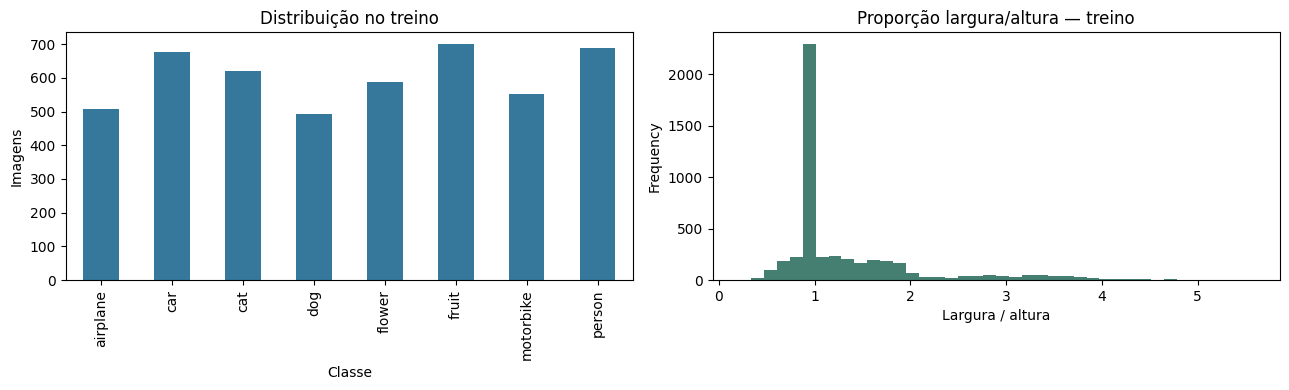

,width,height
count,4829.00,4829.00
mean,234.24,197.59
std,134.82,129.93
min,51.00,55.00
25%,100.00,100.00
50%,234.00,122.00
75%,295.00,256.00
max,2737.00,2665.00


mode
RGB    4829
Name: quantidade, dtype: int64

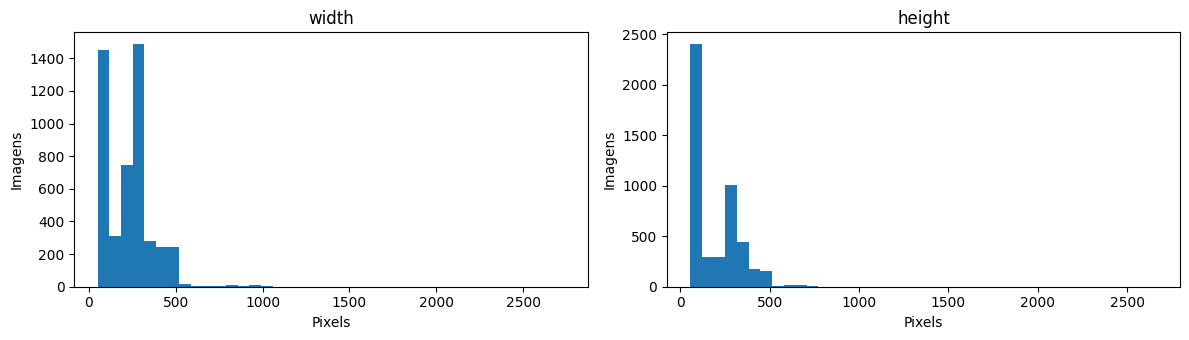

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_df['class'].value_counts().reindex(CLASSES).plot.bar(ax=axes[0], color='#36789b')
axes[0].set(title='Distribuição no treino', ylabel='Imagens', xlabel='Classe')
train_df.assign(aspect=train_df.width/train_df.height)['aspect'].plot.hist(bins=40, ax=axes[1], color='#447f72')
axes[1].set(title='Proporção largura/altura — treino', xlabel='Largura / altura')
plt.tight_layout(); plt.show()
display(train_df[['width','height']].describe().round(2))
display(train_df['mode'].value_counts().rename('quantidade'))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col in zip(axes, ['width','height']):
    ax.hist(train_df[col], bins=40); ax.set(title=col, xlabel='Pixels', ylabel='Imagens')
plt.tight_layout(); plt.show()

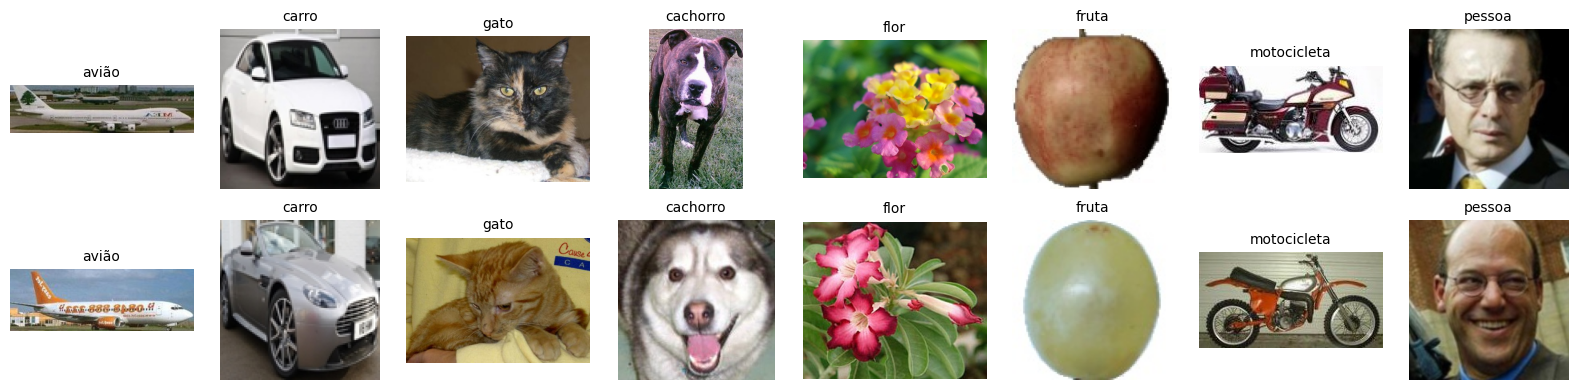

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, cls in enumerate(CLASSES):
    examples = train_df[train_df['class'].eq(cls)].sample(2, random_state=SEED)
    for j, (_, row) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / row.file) as im:
            axes[j,i].imshow(im.convert('RGB'))
        axes[j,i].set_title(CLASSES_PT[i], fontsize=10); axes[j,i].axis('off')
plt.tight_layout(); plt.show()

**Registro para a defesa (preencher após execução):** quais classes predominam? Qual a variação de tamanhos/proporções? Há fundos padronizados, imagens com mais de um objeto, baixa qualidade ou padrões de coleta? Anote exemplos concretos do painel. Não concluir que o dataset é perfeitamente balanceado sem observar as contagens. A amostra visual de duas imagens por classe é ilustrativa, não prova ausência de vieses.

## 7. Pré-processamento e pipeline
- Decodificar em RGB (três canais), redimensionar para 224×224 com interpolação bilinear e padding para manter a proporção; o preenchimento pode criar pistas artificiais, o que será considerado na análise. O tensor entra no modelo com pixels em [0,255].
- A transformação esperada pelos pesos MobileNetV2 é x/127,5 − 1, produzindo [-1,1]. A camada `Rescaling` implementa exatamente essa transformação dentro do modelo; não normalizar novamente.
- Aumentação moderada só no treino: espelhamento horizontal e rotação pequena (±18°). Aumentação não cria imagens independentes para validação/teste. É desabilitada automaticamente na inferência. O espelhamento pode ser inadequado se a tarefa depender de texto/direção, que não são alvos aqui.
- Lotes de 32, embaralhamento só no treino; rótulos one-hot para entropia cruzada categórica e F1 macro do Keras. A validação mantém a ordem do manifesto para alinhar previsões e rótulos.

In [7]:
def decode_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(tf.cast(image, tf.float32), *IMG_SIZE, antialias=True)
    image.set_shape([*IMG_SIZE, 3])
    return image, tf.one_hot(label, N_CLASSES)

def make_dataset(frame, training=False):
    files = [str(DATA_DIR / f) for f in frame.file]
    ds = tf.data.Dataset.from_tensor_slices((files, frame.label.to_numpy(dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
images, labels = next(iter(train_ds))
print('Entrada:', images.shape, '| targets:', labels.shape)
print('Faixa de pixels:', float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Entrada: (32, 224, 224, 3) | targets: (32, 8)
Faixa de pixels: 0.0 255.00006103515625


## 8. Métricas e protocolo experimental
**F1 macro** será a métrica primária de seleção de checkpoint e de recomendação futura: média não ponderada dos F1 das oito classes, dando igual importância às categorias. F1 por classe é a média harmônica de precisão e recall. Precisão = VP/(VP+FP), recall = VP/(VP+FN). **Acurácia** é a proporção de acertos, útil para interpretação geral, mas pode favorecer classes mais frequentes. **Balanced accuracy** é a média dos recalls. Também registramos loss categórica, precisão/recall/F1 por classe e matrizes de confusão bruta e normalizada por linha.

Para a aplicação proposta (organização de fotos), falsos negativos de uma categoria tornam buscas incompletas; falsos positivos contaminam a pasta correspondente. Não há evidência de custo assimétrico crítico, portanto usamos pesos iguais entre classes na métrica primária e não introduzimos pesos de loss sem justificativa empírica. Scores softmax indicam confiança relativa do modelo, não necessariamente probabilidades calibradas.

A regra fixa é: salvar o checkpoint de maior F1 macro na validação; em igualdade, manter o primeiro. Early stopping monitora o mesmo indicador com paciência 4. Não usamos teste. A mesma regra será aplicada a A e B; a recomendação final considerará também custo, estabilidade e erros por classe.

## 9. Transfer learning: base congelada (baseline)
Configuração inicial proposta (não resultado de busca de hiperparâmetros): MobileNetV2 com pesos ImageNet, `include_top=False`, alpha 1, GAP, Dropout 0,2, Dense de oito saídas softmax. GAP reduz 7×7×1280 a 1280 valores, evitando um classificador grande. Dropout atua só no treino para regularizar a cabeça. Adam com LR 0,001, batch 32, até 20 épocas. Loss categórica. Com base congelada, a cabeça tem 1280×8+8 = 10.248 parâmetros treináveis. Esperamos 2.257.984 parâmetros na base e 2.268.232 no total (confirmar pelo `summary`).

`base(..., training=False)` mantém Batch Normalization no modo de inferência. Isso preserva estatísticas aprendidas em ImageNet e prepara o modelo para o futuro fine-tuning. O checkpoint `.keras` salva arquitetura e pesos; a cópia selecionada é o ponto de partida comum de A e B.

In [8]:
from tensorflow import keras
from tensorflow.keras import layers

base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), alpha=1.0,
                                        include_top=False, weights='imagenet')
base.trainable = False
BASE_NAME = base.name
augmentation = keras.Sequential([
    layers.RandomFlip('horizontal', seed=SEED),
    layers.RandomRotation(0.05, fill_mode='reflect', seed=SEED+1),
], name='augmentation')
inputs = keras.Input(shape=(*IMG_SIZE, 3), name='rgb_image')
x = augmentation(inputs)
x = layers.Rescaling(1/127.5, offset=-1, name='mobilenet_preprocess')(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D(name='gap')(x)
x = layers.Dropout(0.2, seed=SEED, name='dropout')(x)
outputs = layers.Dense(N_CLASSES, activation='softmax', name='classifier')(x)
model = keras.Model(inputs, outputs, name='mobilenetv2_natural_images')

def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss=keras.losses.CategoricalCrossentropy(),
              metrics=[keras.metrics.CategoricalAccuracy(name='accuracy'),
                       keras.metrics.F1Score(average='macro', name='f1_macro')])

def count_params(m):
    return {'total': m.count_params(),
            'trainable': sum(int(np.prod(w.shape)) for w in m.trainable_weights),
            'non_trainable': sum(int(np.prod(w.shape)) for w in m.non_trainable_weights)}

compile_model(model, LR)
model.summary()
print('Base:', BASE_NAME, '| parâmetros:', count_params(model))
assert count_params(model)['trainable'] == 10248

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2_natural_images"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Base: mobilenetv2_1.00_224 | parâmetros: {'total': 2268232, 'trainable': 10248, 'non_trainable': 2257984}


In [9]:
BASELINE_PATH = ARTIFACTS / 'baseline_best.keras'
def callbacks_for(path):
    return [keras.callbacks.ModelCheckpoint(str(path), monitor='val_f1_macro', mode='max',
                                            save_best_only=True, verbose=1),
            keras.callbacks.EarlyStopping(monitor='val_f1_macro', mode='max',
                                          patience=PATIENCE, restore_best_weights=False, verbose=1),
            keras.callbacks.TerminateOnNaN()]

BASELINE_PATH.unlink(missing_ok=True)  # inicia um novo experimento da baseline
before = [w.numpy().copy() for w in base.weights]
start = time.perf_counter()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=callbacks_for(BASELINE_PATH))
training_seconds = time.perf_counter() - start
assert all(np.array_equal(a, b.numpy()) for a,b in zip(before, base.weights)), 'Base congelada foi alterada.'
del before
hist = pd.DataFrame(history.history)
hist.index = np.arange(1, len(hist)+1)
hist.index.name = 'epoch'
hist.to_csv(ARTIFACTS / 'baseline_history.csv')
assert np.isfinite(hist[['loss', 'val_loss', 'val_f1_macro']].to_numpy()).all(), 'Treinamento instável: revisar antes de prosseguir.'
best_epoch = int(hist.val_f1_macro.idxmax())
assert BASELINE_PATH.is_file()
baseline = keras.models.load_model(BASELINE_PATH)
print('Melhor época:', best_epoch, '| tempo total (s):', round(training_seconds,2))
print('Checkpoint:', BASELINE_PATH)
config = dict(seed=SEED, dataset_handle=DATASET_HANDLE, dataset_dir=str(DATA_DIR),
              split_sha256=hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
              classes=CLASSES, classes_pt=CLASSES_PT, image_size=list(IMG_SIZE), batch_size=BATCH_SIZE,
              learning_rate=LR, optimizer='Adam', epochs_max=EPOCHS, epochs_run=len(hist),
              best_epoch=best_epoch, patience=PATIENCE, selection='val_f1_macro',
              training_seconds=training_seconds, base_name=BASE_NAME, **count_params(baseline),
              tensorflow=tf.__version__)
(ARTIFACTS / 'baseline_config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False))

Epoch 1/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - accuracy: 0.7972 - f1_macro: 0.7884 - loss: 0.6801
Epoch 1: val_f1_macro improved from None to 0.99678, saving model to artifacts\baseline_best.keras
151/151 ━━━━━━━━━━━━━━━━━━━━ 127s 780ms/step - accuracy: 0.9337 - f1_macro: 0.9313 - loss: 0.2555 - val_accuracy: 0.9971 - val_f1_macro: 0.9968 - val_loss: 0.0296
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.9930 - f1_macro: 0.9923 - loss: 0.0331
Epoch 2: val_f1_macro did not improve from 0.99678
151/151 ━━━━━━━━━━━━━━━━━━━━ 64s 421ms/step - accuracy: 0.9948 - f1_macro: 0.9945 - loss: 0.0287 - val_accuracy: 0.9971 - val_f1_macro: 0.9968 - val_loss: 0.0170
Epoch 3/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.9985 - f1_macro: 0.9984 - loss: 0.0157
Epoch 3: val_f1_macro improved from 0.99678 to 0.99685, saving model to artifacts\baseline_best.keras
151/151 ━━━━━━━━━━━━━━━━━━━━ 63s 420ms/step - accuracy: 0.9979 - f1_macro: 0.9978 - loss: 0.0165 - val

930

## 10. Curvas e avaliação na validação
As curvas mostram aprendizado e generalização ao longo das épocas. Uma diferença treino/validação crescente junto de piora na loss de validação pode indicar overfitting; ambas as curvas ruins podem indicar underfitting, pré-processamento inadequado ou cabeça insuficiente. As métricas de treino são coletadas durante as atualizações e sob aumentação/dropout, enquanto validação usa o modelo em inferência. Portanto, validação superior ao treino não é automaticamente vazamento. O marcador vertical é a época de seleção do checkpoint.

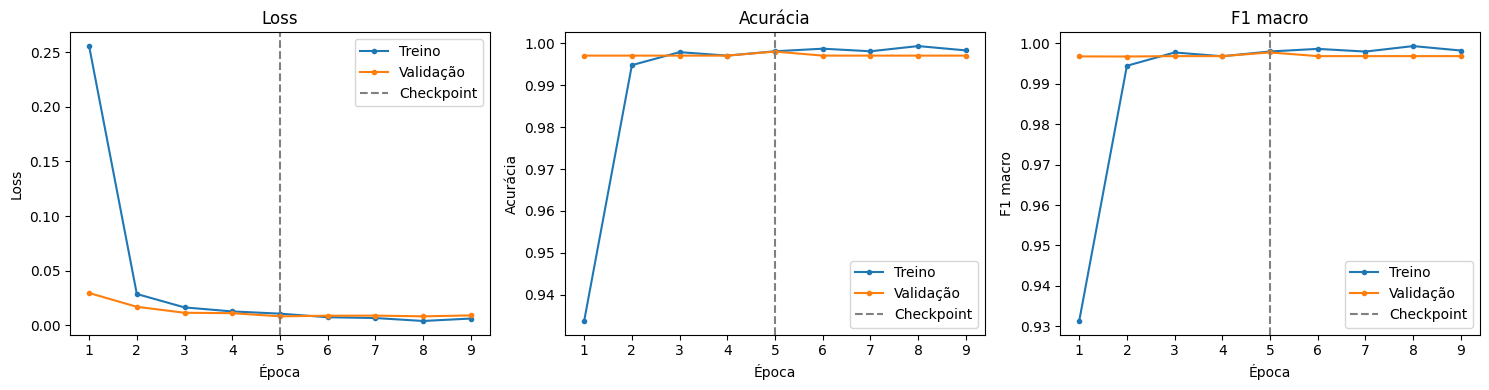

,accuracy,f1_macro,loss,val_accuracy,val_f1_macro,val_loss
epoch,,,,,,
1,0.9337,0.9313,0.2555,0.9971,0.9968,0.0296
2,0.9948,0.9945,0.0287,0.9971,0.9968,0.0170
3,0.9979,0.9978,0.0165,0.9971,0.9969,0.0116
4,0.9971,0.9968,0.0128,0.9971,0.9969,0.0112
5,0.9981,0.9980,0.0107,0.9981,0.9978,0.0083
6,0.9988,0.9986,0.0075,0.9971,0.9969,0.0088
7,0.9981,0.9980,0.0067,0.9971,0.9969,0.0090
8,0.9994,0.9993,0.0040,0.9971,0.9969,0.0083
9,0.9983,0.9982,0.0063,0.9971,0.9969,0.0091


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, metric, name in zip(axes, ['loss','accuracy','f1_macro'], ['Loss','Acurácia','F1 macro']):
    ax.plot(hist.index, hist[metric], marker='.', label='Treino')
    ax.plot(hist.index, hist['val_'+metric], marker='.', label='Validação')
    ax.axvline(best_epoch, color='gray', linestyle='--', label='Checkpoint')
    ax.set(xlabel='Época', ylabel=name, title=name); ax.legend()
plt.tight_layout(); plt.show()
display(hist.round(4))

In [11]:
# Avaliação exclusiva da validação, com o checkpoint selecionado.
val_metrics = baseline.evaluate(val_ds, return_dict=True, verbose=0)
probs = baseline.predict(val_ds, verbose=0)
y_true = val_df.label.to_numpy()
y_pred = probs.argmax(axis=1)
assert len(y_pred) == len(y_true) == 1035
scores = probs.max(axis=1)
results = val_df[['file','class','label']].copy()
results['pred'] = y_pred
results['score'] = scores
results['correct'] = y_true == y_pred
results.to_csv(ARTIFACTS / 'baseline_val_predictions.csv', index=False)
summary = pd.DataFrame([{'condicao':'Base congelada', 'split':'validação',
                        'loss':val_metrics['loss'], 'accuracy':accuracy_score(y_true,y_pred),
                        'f1_macro':f1_score(y_true,y_pred,average='macro',labels=range(N_CLASSES),zero_division=0),
                        'balanced_accuracy':balanced_accuracy_score(y_true,y_pred),
                        'trainable_params':count_params(baseline)['trainable'], 'epochs':len(hist),
                        'best_epoch':best_epoch, 'time_seconds':training_seconds}])
display(summary.round(4))
summary.to_csv(ARTIFACTS / 'baseline_val_metrics.csv', index=False)
report = pd.DataFrame(classification_report(y_true, y_pred, labels=range(N_CLASSES),
                         target_names=CLASSES_PT, zero_division=0, output_dict=True)).T
display(report.round(4))
report.to_csv(ARTIFACTS / 'baseline_val_report.csv')
print('Verificação F1 Keras × sklearn:', val_metrics['f1_macro'], summary.f1_macro.iloc[0])

,condicao,split,loss,accuracy,f1_macro,balanced_accuracy,trainable_params,epochs,best_epoch,time_seconds
0,Base congelada,validação,0.0083,0.9981,0.9978,0.9977,10248,9,5,1053.1013


,precision,recall,f1-score,support
avião,1.0000,0.9817,0.9907,109.0000
carro,1.0000,1.0000,1.0000,145.0000
gato,1.0000,1.0000,1.0000,133.0000
cachorro,0.9906,1.0000,0.9953,105.0000
flor,0.9922,1.0000,0.9961,127.0000
fruta,1.0000,1.0000,1.0000,150.0000
motocicleta,1.0000,1.0000,1.0000,118.0000
pessoa,1.0000,1.0000,1.0000,148.0000
accuracy,0.9981,0.9981,0.9981,0.9981
macro avg,0.9978,0.9977,0.9978,1035.0000


Verificação F1 Keras × sklearn: 0.9977599382400513 0.9977599794525498


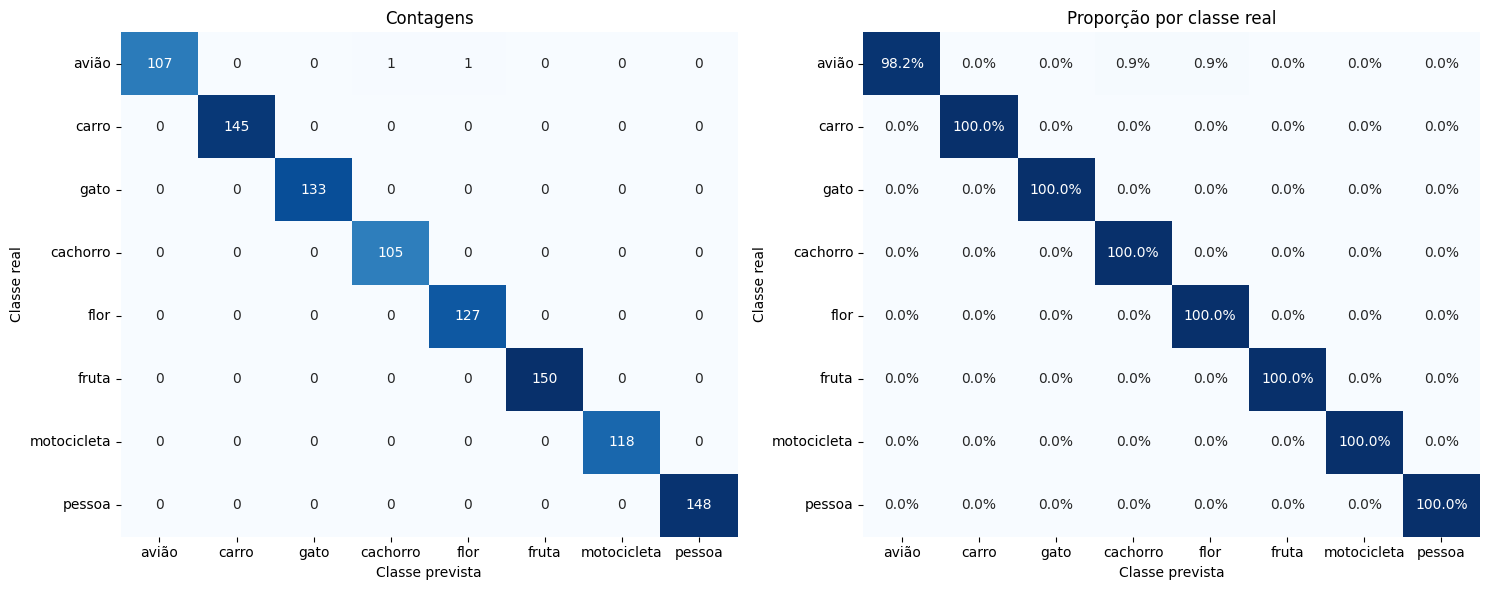

In [12]:
cm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES))
cm_norm = confusion_matrix(y_true, y_pred, labels=range(N_CLASSES), normalize='true')
fig, axes = plt.subplots(1,2,figsize=(15,6))
for ax, mat, fmt, title in zip(axes, [cm, cm_norm], ['d','.1%'], ['Contagens','Proporção por classe real']):
    sns.heatmap(mat, annot=True, fmt=fmt, cmap='Blues', xticklabels=CLASSES_PT,
                yticklabels=CLASSES_PT, ax=ax, cbar=False)
    ax.set(title=title, xlabel='Classe prevista', ylabel='Classe real')
plt.tight_layout(); plt.show()

## 11. Análise visual preliminar dos acertos e erros
Verificar acertos incertos, erros de alto score e principais pares de confusão. O painel preserva as imagens e seus identificadores relativos para comparação futura dos três modelos e Grad-CAM. Se não houver erros, são analisados os acertos de menor score. As hipóteses sobre foco no objeto/fundo não são comprovação causal; o Grad-CAM será usado na etapa final.

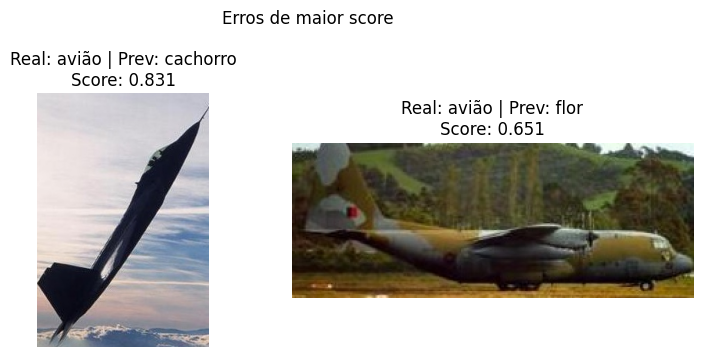

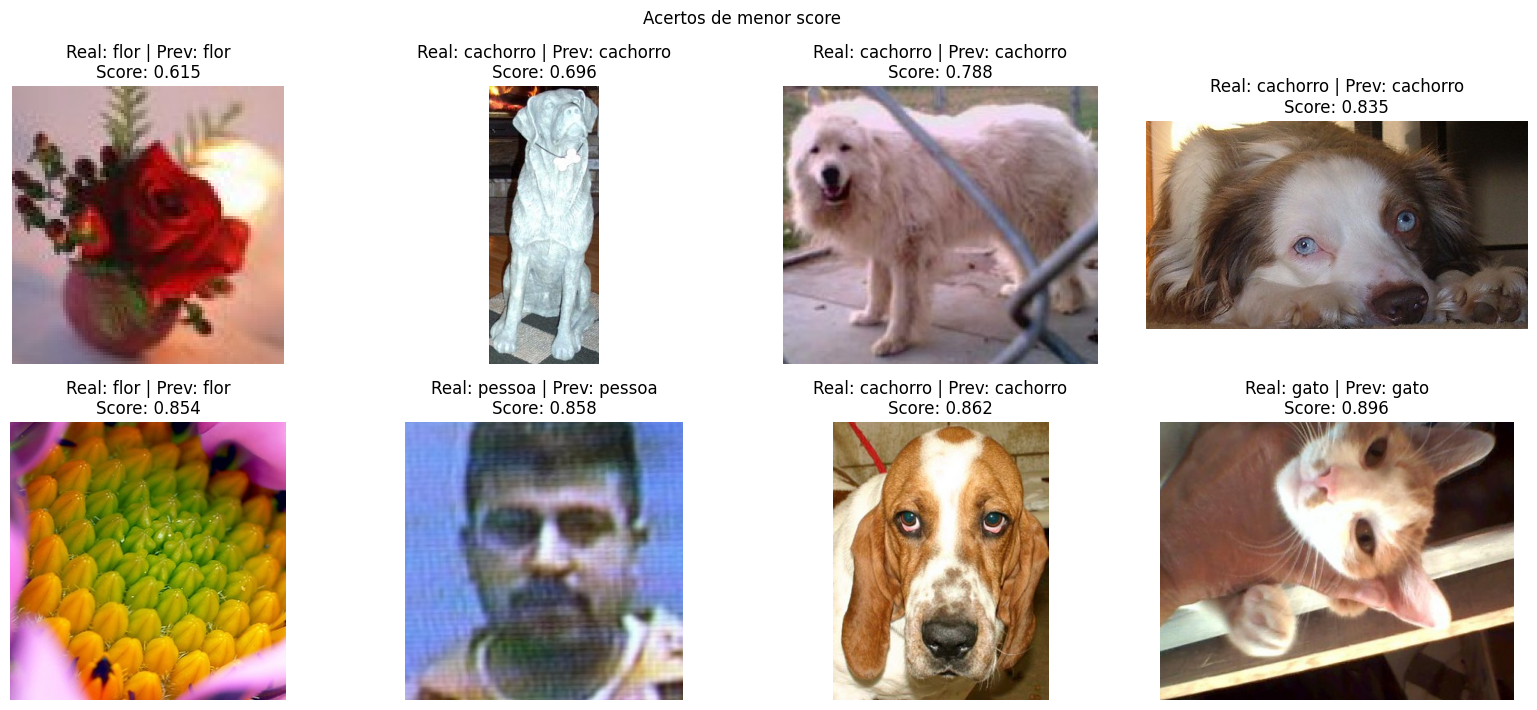

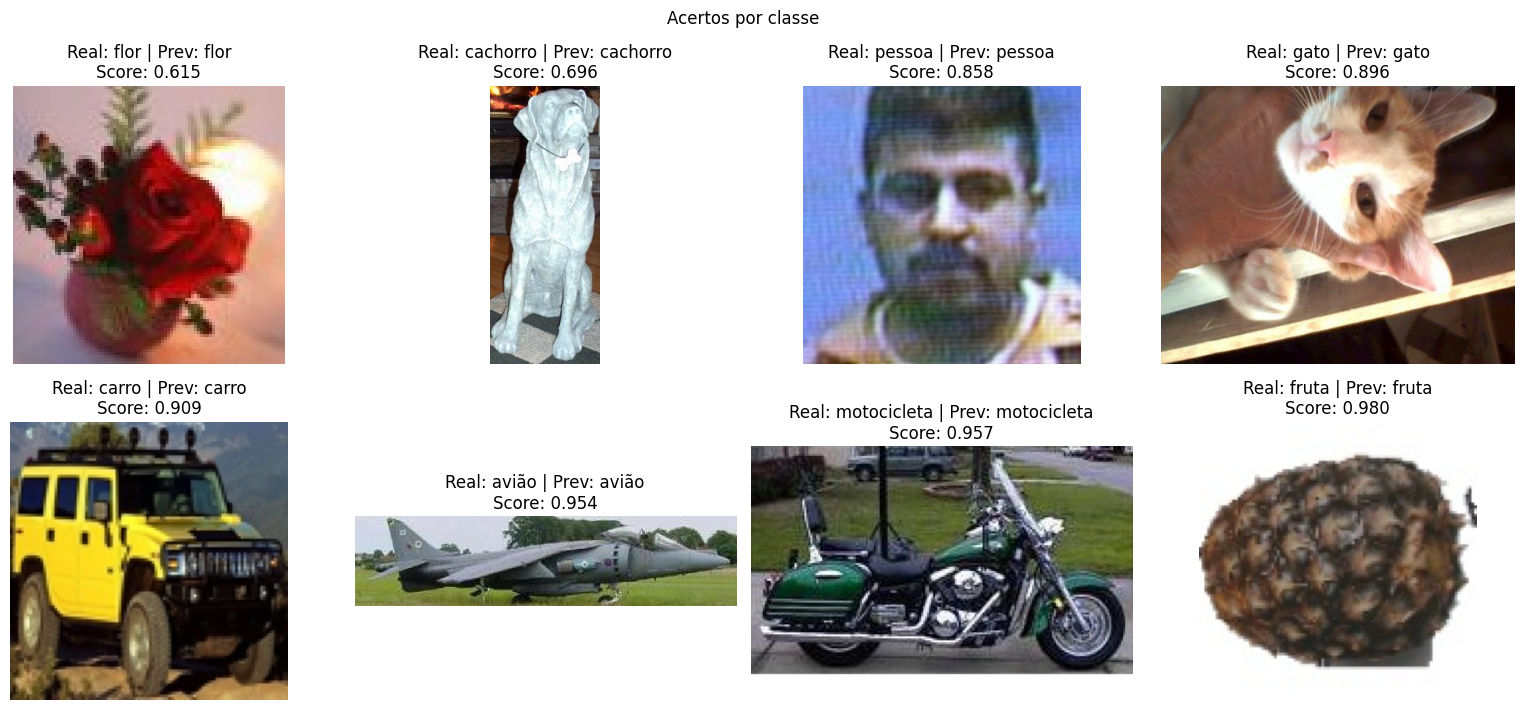

,label,pred,n_erros,real,previsto
0,0,3,1,avião,cachorro
1,0,4,1,avião,flor


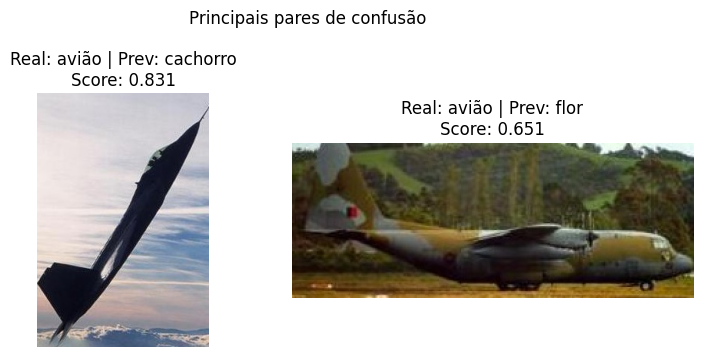

In [13]:
def show_cases(frame, title, limit=8):
    frame = frame.head(limit)
    if frame.empty:
        print(title, ': sem exemplos disponíveis.'); return
    cols = min(4, len(frame)); rows = int(np.ceil(len(frame)/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3.6*rows), squeeze=False)
    for ax, (_, r) in zip(axes.flat, frame.iterrows()):
        with Image.open(DATA_DIR / r.file) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f'Real: {CLASSES_PT[int(r.label)]} | Prev: {CLASSES_PT[int(r.pred)]}\nScore: {r.score:.3f}')
        ax.axis('off')
    for ax in list(axes.flat)[len(frame):]: ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

errors = results[~results.correct].sort_values('score', ascending=False)
correct = results[results.correct].sort_values('score')
show_cases(errors, 'Erros de maior score')
show_cases(correct, 'Acertos de menor score')
# Até um acerto por classe, para representar diferentes categorias.
show_cases(correct.groupby('label', sort=True).head(1), 'Acertos por classe')
if not errors.empty:
    pairs = errors.groupby(['label','pred']).size().sort_values(ascending=False)
    display(pairs.rename('n_erros').reset_index().assign(
        real=lambda x: x.label.map(dict(enumerate(CLASSES_PT))),
        previsto=lambda x: x.pred.map(dict(enumerate(CLASSES_PT)))))
    main = []
    for real, pred in pairs.head(4).index:
        main.append(errors[(errors.label==real)&(errors.pred==pred)].head(2))
    main_cases = pd.concat(main)
    show_cases(main_cases, 'Principais pares de confusão')
else:
    print('Nenhum erro na validação; analisar acertos menos confiantes.')
    main_cases = errors
anchors = pd.concat([main_cases, errors.head(4), correct.head(4), correct.groupby('label').head(1)])
anchors.drop_duplicates('file').to_csv(ARTIFACTS / 'visual_cases_val.csv', index=False)

### 11.1 Discussão dos resultados parciais (preenchimento obrigatório após treinamento)
Não inventar números. Use as saídas anteriores e escreva com as próprias palavras:

- Qual foi a época selecionada, F1 macro, acurácia e loss de validação? Qual o custo de treino?
- O comportamento das curvas aponta para convergência, overfitting ou underfitting? Cite épocas e valores observados.
- Quais classes têm menor recall/F1? Quais confusões predominam e por quê? Há casos com score alto, mas previsão incorreta?
- Descreva pelo menos dois exemplos visuais concretos, com nome de arquivo, classe verdadeira, previsão, score e hipótese. Caso não haja erros, discuta acertos incertos.
- As hipóteses serão testadas na etapa final com comparação das mesmas imagens entre os modelos. Não extrapolar o resultado de validação para imagens reais fora da distribuição.

## 12. Planejamento de fine-tuning A e B (sem treinamento nesta defesa)
**Hipótese:** a adaptação dos filtros mais próximos da saída pode melhorar a representação das oito classes. Ajustar mais blocos pode ajudar se houver diferença de domínio, mas eleva custo e risco de overfitting/esquecimento de características úteis. Não há garantia de ganho.

| Condição | Camadas da base ajustadas | LR | Máximo de épocas |
|---|---|---:|---:|
| Baseline | Nenhuma; apenas cabeça | 0,001 | 20 |
| A — conservadora | Blocos 13–16 + Conv_1 | 0,00001 | 20 adicionais |
| B — mais ampla | Blocos 6–16 + Conv_1 | 0,00001 | 20 adicionais |

A e B iniciarão de **duas cópias independentes do mesmo `baseline_best.keras`**, não de A seguido de B. A variável manipulada será a profundidade do descongelamento. Em ambas: mesmas divisões, pré-processamento, aumento, cabeça, Adam novo, LR, batch, orçamento, métrica de seleção e early stopping. BN permanece congelada e chamada em modo de inferência; a rede é recompilada após mudança de `trainable`. O ganho será comparado com o custo e os erros da baseline. As estratégias são propostas a validar durante a defesa, não experimentos concluídos.

A célula seguinte somente inspeciona, sem alterar a baseline, quais camadas e pesos seriam ajustados em cada estratégia. A função será reutilizada na próxima versão.

In [14]:
import re

def prepare_finetune(first_block):
    m = keras.models.load_model(BASELINE_PATH, compile=False)
    b = m.get_layer(BASE_NAME)
    b.trainable = True
    for layer in b.layers:
        match = re.match(r'block_(\d+)_', layer.name)
        allowed = (match is not None and int(match.group(1)) >= first_block) or layer.name == 'Conv_1'
        layer.trainable = allowed and not isinstance(layer, layers.BatchNormalization)
    assert any(layer.trainable and layer.trainable_weights for layer in b.layers)
    compile_model(m, 1e-5)
    return m

for name, first in [('A',13), ('B',6)]:
    planned = prepare_finetune(first)
    b = planned.get_layer(BASE_NAME)
    updated = [l.name for l in b.layers if l.trainable_weights]
    print(name, '| parâmetros:', count_params(planned))
    print('Camadas com pesos ajustáveis:', ', '.join(updated))
    del planned, b
# Nenhum fit/evaluate de fine-tuning e nenhum acesso preditivo ao teste nesta versão.

A | parâmetros: {'total': 2268232, 'trainable': 1673608, 'non_trainable': 594624}
Camadas com pesos ajustáveis: block_13_expand, block_13_depthwise, block_13_project, block_14_expand, block_14_depthwise, block_14_project, block_15_expand, block_15_depthwise, block_15_project, block_16_expand, block_16_depthwise, block_16_project, Conv_1
B | parâmetros: {'total': 2268232, 'trainable': 2148040, 'non_trainable': 120192}
Camadas com pesos ajustáveis: block_6_expand, block_6_depthwise, block_6_project, block_7_expand, block_7_depthwise, block_7_project, block_8_expand, block_8_depthwise, block_8_project, block_9_expand, block_9_depthwise, block_9_project, block_10_expand, block_10_depthwise, block_10_project, block_11_expand, block_11_depthwise, block_11_project, block_12_expand, block_12_depthwise, block_12_project, block_13_expand, block_13_depthwise, block_13_project, block_14_expand, block_14_depthwise, block_14_project, block_15_expand, block_15_depthwise, block_15_project, block_16_ex

## 13. Caminho para a defesa final e estudo para arguição
Após feedback da professora, executar A e B independentemente; comparar métricas/curvas/matrizes e tempos incluindo épocas adicionais e custo total desde a baseline. Analisar as mesmas imagens de validação para erros corrigidos, persistentes e novos. Usar Grad-CAM em mapas espaciais finais (candidata: `out_relu` da base, saída 7×7×1280), explicitando a classe-alvo, preferencialmente os logits antes da softmax. O Grad-CAM agrega gradientes da classe-alvo por canal, combina os mapas com esses pesos e aplica ReLU para destacar regiões com contribuição positiva; não é segmentação nem prova causal. Para comparar modelos na mesma imagem, fixar também a classe-alvo quando pertinente. A resolução espacial reduzida limita a precisão do mapa.

Escolher o modelo usando apenas validação e critérios já definidos; somente depois avaliar os três checkpoints no teste reservado, sem novos ajustes. Salvar o recomendado, os índices/classes e o pré-processamento, carregar sem treinar e testar uma imagem externa com fonte indicada. A imagem externa não substitui o teste.

**Perguntas para ensaiar:**
1. Por que a MobileNetV2 é eficiente? Qual a diferença entre depthwise e pointwise? Em que a V2 melhora a V1? Quando a conexão residual pode existir?
2. Por que usar 224×224, RGB e [-1,1]? Por que não aplicar a normalização duas vezes? Qual a limitação do padding?
3. Por que estratificação e teste reservado? Qual a diferença entre validação e teste? Como duplicatas causam vazamento?
4. Por que usar softmax e entropia cruzada categórica? Como interpretar F1 macro, acurácia, recall e matriz de confusão?
5. O que de fato treina na baseline? Por que GAP e Dropout? Qual o efeito de BN e de `training=False`?
6. Como interpretar as curvas? Por que selecionar por validação e não por treino? Por que o maior score não garante que uma previsão esteja correta?
7. Qual a diferença controlada entre A e B? Por que partir do mesmo checkpoint, recompilar e reduzir LR? Por que não descongelar tudo imediatamente?
8. Como Grad-CAM funciona? O que ele não demonstra? Como recomendar um modelo se fine-tuning não melhorar?

## 14. Referências
- Sandler et al. (2018). [MobileNetV2: Inverted Residuals and Linear Bottlenecks](https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html). CVPR.
- Roy, P. et al. [Natural Images — Kaggle](https://www.kaggle.com/datasets/prasunroy/natural-images); [repositório dos autores](https://github.com/prasunroy/cnn-on-degraded-images).
- Keras. [MobileNet models](https://keras.io/api/applications/mobilenet/mobilenet_models/); [Transfer learning & fine-tuning](https://keras.io/guides/transfer_learning/); [F1Score](https://keras.io/api/metrics/classification_metrics/#f1score-class).
- Kaggle. [KaggleHub](https://github.com/Kaggle/kagglehub).
- Selvaraju et al. (2017). [Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization](https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html).
- Lauda CNN 2026_2, disciplina Inteligência Computacional/Machine Learning (material da professora).

**Estado desta versão:** código e metodologia iniciais; execução real, revisão dos resultados, nomes e atualização da declaração de IA ainda necessários antes da entrega. Nenhuma métrica foi fabricada.